In [1]:
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense,Dropout,MaxPool2D,GlobalAveragePooling2D
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix

I0000 00:00:1789541099.651581   18668 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789541099.718327   18668 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789541101.243659   18668 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
training_path = "../Datasets/data/train"
testing_path = "../Datasets/data/test"
valid_path = "../Datasets/data/vaild"

In [3]:
train_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range = 10,
    zoom_range = 0.2,
    horizontal_flip = True
)
test_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)
valid_dataug = ImageDataGenerator(
    preprocessing_function = preprocess_input
)

In [4]:
training_set = train_dataug.flow_from_directory(
    training_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
valid_set = valid_dataug.flow_from_directory(
    valid_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary"
)
testing_set = test_dataug.flow_from_directory(
    testing_path,
    target_size = (224,224),
    batch_size = 16,
    class_mode = "binary",
    shuffle = False
)

Found 113924 images belonging to 2 classes.
Found 15080 images belonging to 2 classes.
Found 20770 images belonging to 2 classes.


In [5]:
base_model = EfficientNetV2B0(weights="imagenet",include_top=False,input_shape=(224,224,3))

I0000 00:00:1789053819.412489   15714 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
base_model.trainable = False

In [7]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128,activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(128, activation='relu')(x)
output = Dense(1,activation="sigmoid")(x)

In [8]:
model = Model(inputs = base_model.input,outputs = output)

In [9]:
model.compile(optimizer=Adam(learning_rate=0.002),metrics=["accuracy"],loss="binary_crossentropy")

In [ ]:
early_stop = EarlyStopping(monitor="loss",patience=3,restore_best_weights=True)

In [13]:
history = model.fit(training_set,validation_data=(valid_set),epochs=4,callbacks=[early_stop])

Epoch 1/4
7152/7152 ━━━━━━━━━━━━━━━━━━━━ 1136s 159ms/step - accuracy: 0.9994 - loss: 0.0050 - val_accuracy: 0.9997 - val_loss: 0.0020
Epoch 2/4
7152/7152 ━━━━━━━━━━━━━━━━━━━━ 1094s 153ms/step - accuracy: 0.9995 - loss: 0.0036 - val_accuracy: 0.9999 - val_loss: 6.1927e-04
Epoch 3/4
7152/7152 ━━━━━━━━━━━━━━━━━━━━ 1084s 151ms/step - accuracy: 0.9997 - loss: 0.0026 - val_accuracy: 0.9996 - val_loss: 0.0040
Epoch 4/4
7152/7152 ━━━━━━━━━━━━━━━━━━━━ 1065s 149ms/step - accuracy: 0.9997 - loss: 0.0044 - val_accuracy: 0.9997 - val_loss: 0.0019


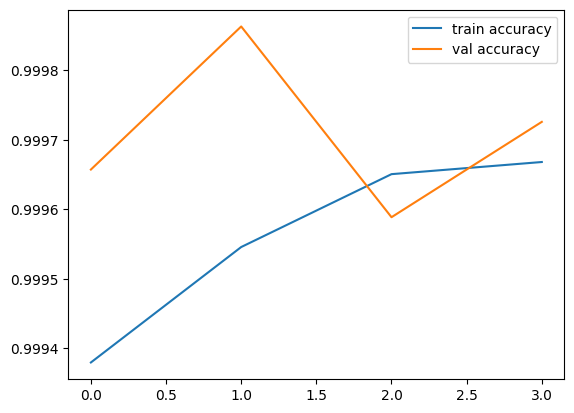

In [14]:
plt.plot(history.history['accuracy'],label = "train accuracy")
plt.plot(history.history['val_accuracy'],label = "val accuracy")
plt.legend()
plt.show()

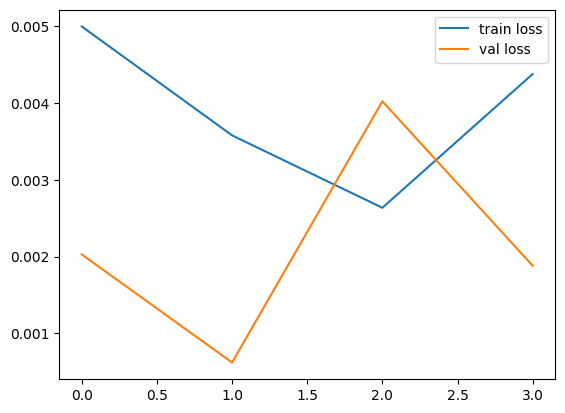

In [15]:
plt.plot(history.history['loss'],label = "train loss")
plt.plot(history.history['val_loss'],label = "val loss")
plt.legend()
plt.show()

In [16]:
prediction = model.predict(testing_set)

1299/1299 ━━━━━━━━━━━━━━━━━━━━ 113s 78ms/step


In [17]:
true_prediction = (prediction > 0.5).astype(int)

In [18]:
y_true = testing_set.classes

In [6]:
training_set.class_indices

{'Medical': 0, 'Non medical': 1}

In [19]:
print(classification_report(y_true,true_prediction))
confusion_matrix(y_true,true_prediction)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10385
           1       1.00      1.00      1.00     10385

    accuracy                           1.00     20770
   macro avg       1.00      1.00      1.00     20770
weighted avg       1.00      1.00      1.00     20770



array([[10384,     1],
       [    7, 10378]])

In [20]:
model.save("medical_or_not_model.keras")